# Métodos de la revisión de literatura

Explicaciones de los métodos que aparecen en los artículos de mi revisión de literatura. Los métodos están organizados **por función**: cada función es una sección de nivel 1 y cada método es una subsección dentro de ella.

Cada método se explica como una **narrativa con orden lógico**, del problema a la aplicación: el problema que resuelve, la idea central con el caso más simple, la formulación paso a paso, el caso que lo rompe, los requisitos previos, la aplicación a puentes y un cierre de síntesis (requisitos, fortalezas y debilidades, relación con otros métodos y uso en la literatura). En cada paso van juntas la explicación, la fórmula en LaTeX (con el significado de cada símbolo y su descripción en palabras), el código, la gráfica y su interpretación.

> 📝 La sección 1.1 (EMD) todavía está escrita en el formato anterior, por bloques (concepto, procedimiento, fórmulas, código, gráficas, fortalezas y debilidades, uso en la literatura).

Los widgets interactivos (`ipywidgets`) van acompañados de una gráfica estática equivalente, porque GitHub no los muestra.

El texto está en español; el código, en inglés.

## Tabla de contenido

| Función | Método |
|---|---|
| [1. Descomposición de señales](#descomposicion-de-senales) | [1.1 EMD (Empirical Mode Decomposition)](#emd) |
| [2. Envolvente de amplitud / amplitud instantánea](#envolvente-de-amplitud) | [2.1 Transformada de Hilbert](#transformada-de-hilbert) (pasos [0](#hilbert-paso-0)–[9](#hilbert-paso-9): del problema a la aplicación en puentes, con HHT y MAC) |

### Configuración

Librerías y estilo de gráficas que usan todos los métodos (ver `requirements.txt`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.signal import argrelextrema, hilbert
from PyEMD import EMD

# Shared plot style: thin lines, recessive grid, no top/right spines
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e3e2de",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 1.4,
    "legend.frameon": False,
})

# Fixed color roles (same meaning in every plot)
COLOR_SIGNAL = "#8a8984"   # raw / measured signal (neutral gray)
COLOR_1 = "#2a78d6"        # first component / mode 1 (blue)
COLOR_2 = "#eb6834"        # second component / mode 2 (orange)
COLOR_3 = "#1baf7a"        # third series: reference / mean (aqua)
COLOR_TRUE = "#0b0b0b"     # exact (true) reference curve, dashed

rng = np.random.default_rng(seed=42)  # reproducible example noise

<a id="descomposicion-de-senales"></a>
# 1. Descomposición de señales

Métodos que separan una señal en componentes más simples (por ejemplo, una componente por cada frecuencia dominante), para poder analizar cada una por separado.

<a id="emd"></a>
## 1.1 EMD (Empirical Mode Decomposition)

### Concepto

La **descomposición empírica en modos** (EMD, Huang et al., 1998) separa una señal en un conjunto de componentes llamadas **IMF** (*Intrinsic Mode Functions*, funciones de modo intrínseco). Cada IMF oscila alrededor de cero y tiene aproximadamente **una sola frecuencia dominante**. La primera IMF contiene las oscilaciones más rápidas y las siguientes son cada vez más lentas; lo que sobra al final es un **residuo** (la tendencia).

Si se suman todas las IMF y el residuo, se recupera exactamente la señal original.

Se llama **"empírica"** porque no supone funciones base fijas (como los senos y cosenos de la transformada de Fourier, o las *wavelets*): las componentes salen de la propia señal, a partir de sus máximos y mínimos locales. Por eso se adapta bien a señales **no estacionarias** (cuyas propiedades cambian en el tiempo) y **no lineales**.

Para qué sirve: aislar cada componente de frecuencia de una señal medida (por ejemplo, la respuesta de un vehículo que cruza un puente, que mezcla varios modos de vibración y ruido) para después analizarla sola, por ejemplo con la transformada de Hilbert (sección 2.1).

Una función es IMF si cumple dos condiciones:

1. El número de extremos (máximos + mínimos) y el número de cruces por cero son iguales o difieren como máximo en uno.
2. En todo instante, el promedio de la envolvente superior (que une los máximos) y la inferior (que une los mínimos) es cero, es decir, la función oscila de forma pareja alrededor de cero.

### Descripción del procedimiento

El proceso para extraer cada IMF se llama **cribado** (*sifting*):

1. **Envolventes.** Se ubican todos los máximos locales de la señal y se unen con una curva suave (un **spline cúbico**): esa es la envolvente superior $e_{max}(t)$. Se hace lo mismo con los mínimos locales para obtener la envolvente inferior $e_{min}(t)$.
2. **Media y resta.** Se calcula la media de las dos envolventes, $m(t)$, y se resta a la señal: $h(t) = x(t) - m(t)$.
3. **Repetir.** Se repiten los pasos 1 y 2 sobre $h(t)$ (tomando $h$ como la nueva señal) hasta que el resultado oscile de forma pareja alrededor de cero, es decir, hasta que cumpla las condiciones de IMF (en la práctica se usa un criterio de parada, por ejemplo, que $h$ casi no cambie entre dos iteraciones). Ese resultado es la **primera IMF**, $c_1(t)$, la de frecuencia más alta.
4. **Siguientes IMF.** Se resta la IMF de la señal, $r_1(t) = x(t) - c_1(t)$, y se repite todo el proceso sobre $r_1(t)$ para obtener $c_2(t)$, luego $c_3(t)$, etc., cada una de menor frecuencia.
5. **Fin.** El proceso termina cuando lo que queda, $r_n(t)$, ya no tiene oscilaciones (es monótono o tiene a lo sumo un extremo): ese es el **residuo**.

### Fórmulas

**Media de las envolventes**

$$
m(t) = \frac{e_{max}(t) + e_{min}(t)}{2}
$$

Donde:

- $m(t)$: media local de la señal en el instante $t$ (la "línea central" alrededor de la cual oscila).
- $e_{max}(t)$: envolvente superior, spline cúbico que pasa por todos los máximos locales.
- $e_{min}(t)$: envolvente inferior, spline cúbico que pasa por todos los mínimos locales.
- $t$: tiempo.

En palabras: en cada instante se toma el punto medio entre la envolvente de arriba y la de abajo. Si la señal oscilara perfectamente alrededor de cero, esta media sería cero en todo momento.

**Paso de cribado**

$$
h(t) = x(t) - m(t)
$$

Donde:

- $h(t)$: señal candidata a IMF después de un paso de cribado.
- $x(t)$: señal sobre la que se está cribando (la original en la primera iteración, o el $h$ anterior en las siguientes).
- $m(t)$: media de las envolventes (fórmula anterior).

En palabras: a la señal se le quita su línea central local, de modo que lo que queda oscila más cerca de cero. Repitiendo esto varias veces se obtiene una IMF.

**Reconstrucción de la señal**

$$
x(t) = \sum_{i=1}^{n} c_i(t) + r_n(t)
$$

Donde:

- $x(t)$: señal original.
- $c_i(t)$: IMF número $i$ ($i = 1$ es la de mayor frecuencia, $i = n$ la de menor).
- $n$: número total de IMF extraídas.
- $r_n(t)$: residuo final (tendencia que queda después de extraer las $n$ IMF).

En palabras: la señal original es exactamente la suma de todas sus IMF más el residuo. La EMD no pierde información, solo la reparte en componentes.

### Código

**Señal de ejemplo:** dos componentes senoidales de 5.65 Hz y 22.62 Hz (frecuencias del ejemplo de la sección 2.1) más ruido blanco gaussiano. Se usa la clase `EMD` de la librería PyEMD (paquete `EMD-signal`).

In [2]:
# --- Example signal: two sinusoids + white noise ---
fs = 500.0                       # sampling frequency (Hz)
duration = 2.0                   # signal length (s)
t = np.arange(0, duration, 1 / fs)

f_low, f_high = 5.65, 22.62      # component frequencies (Hz)
component_low = 1.0 * np.sin(2 * np.pi * f_low * t)
component_high = 0.5 * np.sin(2 * np.pi * f_high * t)
noise = 0.15 * rng.standard_normal(t.size)

signal = component_low + component_high + noise

# --- Run EMD ---
emd = EMD()
emd.emd(signal, t)
imfs, residue = emd.get_imfs_and_residue()
print(f"Number of IMFs: {imfs.shape[0]}")


def dominant_frequency(x, fs):
    # Frequency of the largest FFT peak (ignoring the DC term)
    spectrum = np.abs(np.fft.rfft(x - x.mean()))
    freqs = np.fft.rfftfreq(x.size, 1 / fs)
    return freqs[np.argmax(spectrum[1:]) + 1]


for i, imf in enumerate(imfs, start=1):
    print(f"IMF {i}: dominant frequency = {dominant_frequency(imf, fs):6.2f} Hz, "
          f"RMS = {np.sqrt(np.mean(imf**2)):.3f}")

# --- Check the reconstruction x(t) = sum(c_i) + r_n ---
reconstruction = imfs.sum(axis=0) + residue
print(f"Max reconstruction error: {np.max(np.abs(signal - reconstruction)):.2e}")

Number of IMFs: 6
IMF 1: dominant frequency = 157.00 Hz, RMS = 0.116
IMF 2: dominant frequency =  22.50 Hz, RMS = 0.093
IMF 3: dominant frequency =  22.50 Hz, RMS = 0.350
IMF 4: dominant frequency =   5.50 Hz, RMS = 0.708
IMF 5: dominant frequency =   2.00 Hz, RMS = 0.028
IMF 6: dominant frequency =   1.00 Hz, RMS = 0.007
Max reconstruction error: 1.73e-18


Para ver el cribado "por dentro", la siguiente función implementa **un paso de cribado** a mano (pasos 1 y 2 del procedimiento) con `scipy`, sin usar PyEMD.

In [3]:
def sifting_step(x, t):
    # Local maxima and minima (indices)
    idx_max = argrelextrema(x, np.greater)[0]
    idx_min = argrelextrema(x, np.less)[0]

    # Cubic-spline envelopes through the extrema
    upper_envelope = CubicSpline(t[idx_max], x[idx_max])(t)
    lower_envelope = CubicSpline(t[idx_min], x[idx_min])(t)

    # Mean envelope m(t) and candidate IMF h(t) = x(t) - m(t)
    mean_envelope = (upper_envelope + lower_envelope) / 2
    h = x - mean_envelope
    return idx_max, idx_min, upper_envelope, lower_envelope, mean_envelope, h


# Noise-free version of the signal, so the extrema are easy to see
clean_signal = component_low + component_high
idx_max, idx_min, upper_env, lower_env, mean_env, h1 = sifting_step(clean_signal, t)

### Gráficas

**(a) Un paso de cribado.** La señal (sin ruido, para que se vean los extremos), sus máximos y mínimos, las envolventes de spline cúbico y la media $m(t)$. Abajo, $h(t) = x(t) - m(t)$ comparado con la componente rápida real: después de un solo paso ya se parece mucho a la componente de 22.62 Hz, porque $m(t)$ capturó casi toda la componente lenta.

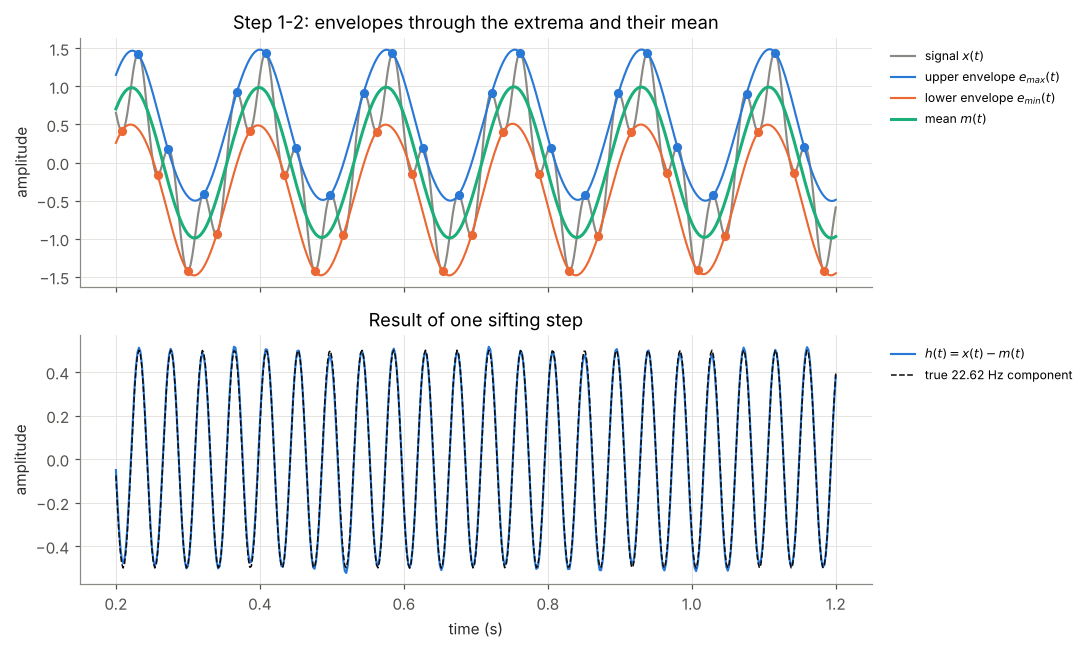

In [4]:
window = (t >= 0.2) & (t <= 1.2)   # zoom into 1 s, away from the edges

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax = axes[0]
ax.plot(t[window], clean_signal[window], color=COLOR_SIGNAL, label="signal $x(t)$")
ax.plot(t[window], upper_env[window], color=COLOR_1, label="upper envelope $e_{max}(t)$")
ax.plot(t[window], lower_env[window], color=COLOR_2, label="lower envelope $e_{min}(t)$")
ax.plot(t[window], mean_env[window], color=COLOR_3, linewidth=2, label="mean $m(t)$")
in_window = lambda idx: idx[(t[idx] >= 0.2) & (t[idx] <= 1.2)]
ax.plot(t[in_window(idx_max)], clean_signal[in_window(idx_max)], "o", ms=5, color=COLOR_1)
ax.plot(t[in_window(idx_min)], clean_signal[in_window(idx_min)], "o", ms=5, color=COLOR_2)
ax.set_ylabel("amplitude")
ax.set_title("Step 1-2: envelopes through the extrema and their mean")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

ax = axes[1]
ax.plot(t[window], h1[window], color=COLOR_1, label="$h(t) = x(t) - m(t)$")
ax.plot(t[window], component_high[window], "--", color=COLOR_TRUE, linewidth=1,
        label="true 22.62 Hz component")
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("Result of one sifting step")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)

fig.tight_layout()
plt.show()

**(b) Señal y sus IMF.** Arriba la señal con ruido; debajo cada IMF y el residuo. La primera IMF recoge sobre todo el ruido (frecuencias más altas); luego aparecen las componentes de 22.62 Hz y de 5.65 Hz (por el ruido, parte de la componente de 22.62 Hz puede repartirse en dos IMF vecinas, una forma de mezcla de modos), y al final IMF de baja frecuencia con muy poca energía (en parte, efectos de borde y restos de ruido).

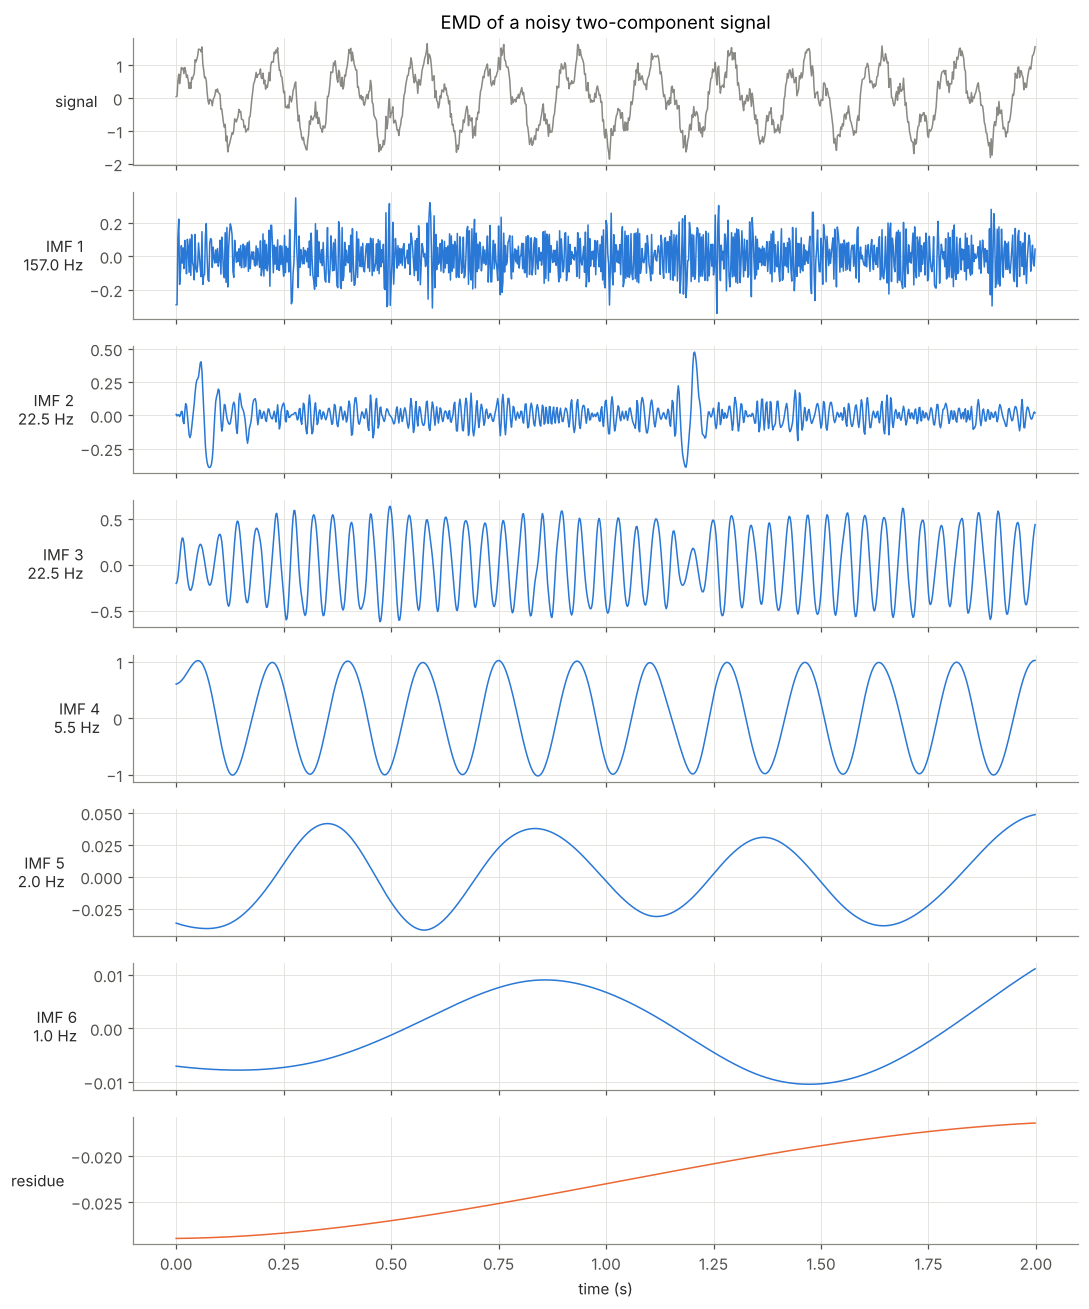

In [5]:
n_imfs = imfs.shape[0]
fig, axes = plt.subplots(n_imfs + 2, 1, figsize=(10, 1.5 * (n_imfs + 2)), sharex=True)

axes[0].plot(t, signal, color=COLOR_SIGNAL, linewidth=1)
axes[0].set_ylabel("signal", rotation=0, ha="right", va="center")

for i, imf in enumerate(imfs):
    f_dom = dominant_frequency(imf, fs)
    axes[i + 1].plot(t, imf, color=COLOR_1, linewidth=1)
    axes[i + 1].set_ylabel(f"IMF {i + 1}\n{f_dom:.1f} Hz", rotation=0, ha="right", va="center")

axes[-1].plot(t, residue, color=COLOR_2, linewidth=1)
axes[-1].set_ylabel("residue", rotation=0, ha="right", va="center")
axes[-1].set_xlabel("time (s)")
axes[0].set_title("EMD of a noisy two-component signal")

fig.tight_layout()
plt.show()

**(c) IMF frente a las componentes reales.** Para cada componente se elige automáticamente, entre las IMF con frecuencia dominante cercana, la de mayor energía, y se compara con la componente verdadera. La coincidencia es buena en el centro y empeora cerca de los bordes (**efecto de borde**: el spline no tiene extremos fuera de la señal para apoyarse).

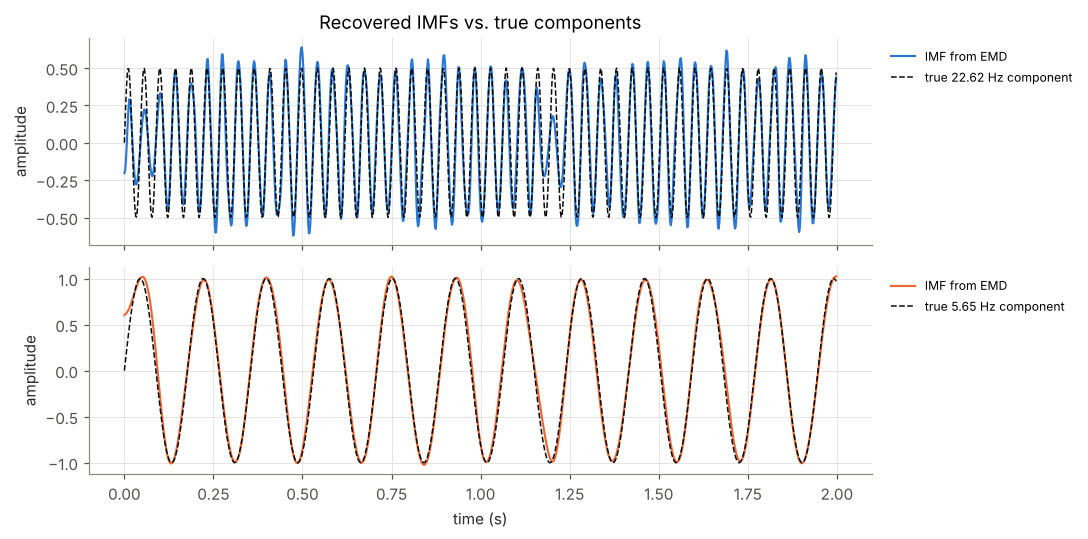

In [6]:
def pick_imf(imfs, fs, target_freq, tolerance=2.0):
    # Among the IMFs whose dominant frequency is within tolerance of the
    # target, return the one with the largest energy (RMS)
    freqs = np.array([dominant_frequency(imf, fs) for imf in imfs])
    rms = np.sqrt(np.mean(imfs**2, axis=1))
    candidates = np.where(np.abs(freqs - target_freq) <= tolerance)[0]
    return imfs[candidates[np.argmax(rms[candidates])]]


imf_high = pick_imf(imfs, fs, f_high)
imf_low = pick_imf(imfs, fs, f_low)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, imf, true, color, f in [
    (axes[0], imf_high, component_high, COLOR_1, f_high),
    (axes[1], imf_low, component_low, COLOR_2, f_low),
]:
    ax.plot(t, imf, color=color, label="IMF from EMD")
    ax.plot(t, true, "--", color=COLOR_TRUE, linewidth=1, label=f"true {f} Hz component")
    ax.set_ylabel("amplitude")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
axes[0].set_title("Recovered IMFs vs. true components")
axes[1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

**(d) Debilidad: mezcla de modos.** Si las dos frecuencias están muy cerca (aquí 5.65 Hz y 7.0 Hz, relación menor que 2), la EMD no puede separarlas: las dos quedan en la **misma IMF**, que aparece como una oscilación con "pulsos" (batido).

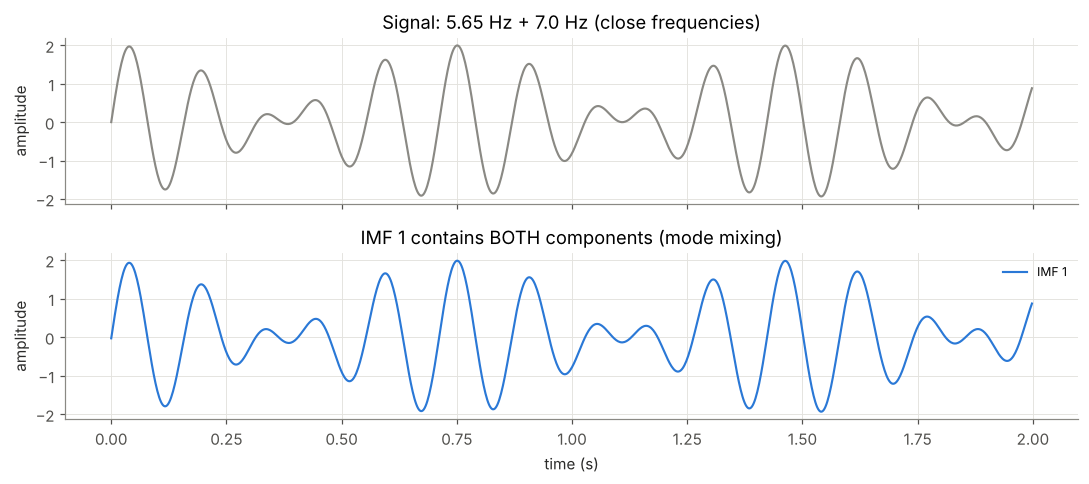

Number of IMFs: 4; RMS share of IMF 1: 100%


In [7]:
f_close = 7.0                                   # close to f_low = 5.65 Hz
close_signal = np.sin(2 * np.pi * f_low * t) + np.sin(2 * np.pi * f_close * t)

emd_close = EMD()
emd_close.emd(close_signal, t)
imfs_close, _ = emd_close.get_imfs_and_residue()

fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
axes[0].plot(t, close_signal, color=COLOR_SIGNAL)
axes[0].set_title(f"Signal: {f_low} Hz + {f_close} Hz (close frequencies)")
axes[0].set_ylabel("amplitude")
axes[1].plot(t, imfs_close[0], color=COLOR_1, label="IMF 1")
axes[1].set_title("IMF 1 contains BOTH components (mode mixing)")
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("amplitude")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

print(f"Number of IMFs: {imfs_close.shape[0]}; "
      f"RMS share of IMF 1: {np.sqrt(np.mean(imfs_close[0]**2)) / np.sqrt(np.mean(close_signal**2)):.0%}")

### Fortalezas y debilidades

**Fortalezas**

- **Adaptativa:** las componentes se obtienen de la propia señal; no hay que elegir una base (senos, *wavelet* madre, etc.).
- **Apta para señales no estacionarias y no lineales**, donde Fourier supone, en cambio, que la señal es estacionaria y la representa con senos de amplitud constante.
- **Reconstrucción exacta:** la suma de IMF + residuo devuelve la señal original.
- Cada IMF es una señal de una sola componente, ideal para aplicar después la **transformada de Hilbert** (EMD + Hilbert = transformada de Hilbert-Huang, HHT).

**Debilidades y limitaciones**

- **Mezcla de modos (*mode mixing*):** dos frecuencias cercanas (relación de frecuencias menor que ~2) pueden quedar en la misma IMF, como en la gráfica (d); también una misma componente puede repartirse entre varias IMF cuando hay ruido o intermitencias.
- **Efectos de borde:** cerca de los extremos de la señal no hay máximos/mínimos para apoyar los splines, y las envolventes se desvían; el error se propaga hacia adentro.
- **Sensibilidad al ruido:** el ruido agrega extremos falsos, genera IMF adicionales y puede cambiar qué componente cae en cada IMF.
- **Sin fundamento matemático cerrado:** se define como un algoritmo, no con una fórmula analítica; el resultado depende del criterio de parada del cribado y del tipo de interpolación, y es difícil de analizar teóricamente.
- **Variantes que lo mitigan:**
  - **EEMD** (*Ensemble EMD*, Wu y Huang, 2009): agrega muchas realizaciones de ruido blanco a la señal, aplica EMD a cada una y promedia las IMF; el ruido añadido ayuda a separar las escalas y reduce la mezcla de modos.
  - **CEEMDAN** (*Complete EEMD with Adaptive Noise*, Torres et al., 2011): versión mejorada de la EEMD en la que la reconstrucción es exacta y se necesitan menos realizaciones.
  - Ambas están disponibles en PyEMD (`EEMD`, `CEEMDAN`).

### Uso en la literatura

- **Origen del método:** Huang, N. E., Shen, Z., Long, S. R., Wu, M. C., Shih, H. H., Zheng, Q., Yen, N.-C., Tung, C. C. y Liu, H. H. (1998). The empirical mode decomposition and the Hilbert spectrum for nonlinear and non-stationary time series analysis. *Proceedings of the Royal Society of London A*, 454, 903–995.
- **Artículos de mi revisión:** *(por completar a medida que aparezca en los artículos revisados)*. En la literatura de monitoreo indirecto de puentes con vehículos, la EMD se usa típicamente para separar la componente de cada modo del puente en la respuesta del vehículo antes de aplicar la transformada de Hilbert (sección 2.1).

<a id="envolvente-de-amplitud"></a>
# 2. Envolvente de amplitud / amplitud instantánea

Métodos que calculan, en cada instante, la amplitud "real" de una oscilación (su envolvente), sin las subidas y bajadas propias de cada ciclo. A menudo también entregan la fase y la frecuencia instantáneas.

<a id="transformada-de-hilbert"></a>
## 2.1 Transformada de Hilbert

La explicación sigue un orden lógico, del problema a la aplicación en puentes:

| Paso | Contenido |
|---|---|
| [0](#hilbert-paso-0) | Configuración y funciones auxiliares |
| [1](#hilbert-paso-1) | El problema: ver cómo cambia la amplitud de una vibración |
| [2](#hilbert-paso-2) | La idea: una copia desfasada 90° |
| [3](#hilbert-paso-3) | Señal analítica y amplitud instantánea |
| [4](#hilbert-paso-4) | Frecuencia instantánea |
| [5](#hilbert-paso-5) | ¿Solo funciona con senoidales? (condición de Bedrosian) |
| [6](#hilbert-paso-6) | El caso que lo rompe: varias frecuencias mezcladas |
| [7](#hilbert-paso-7) | Requisitos previos: preparar la señal (pasabanda y EMD) |
| [8](#hilbert-paso-8) | Aplicación a un puente: de la amplitud a la forma modal |
| [9](#hilbert-paso-9) | Síntesis: requisitos, fortalezas y debilidades, relación con otros métodos, literatura |

<a id="hilbert-paso-0"></a>
### Paso 0. Configuración

Parámetros base del ejemplo y funciones auxiliares que se reutilizan en todo el método:

| Parámetro | Valor |
|---|---|
| Puente | simplemente apoyado, $L = 15$ m |
| Velocidad del vehículo | $v = 2$ m/s (duración del cruce $L/v = 7.5$ s) |
| Frecuencia de muestreo | $f_s = 200$ Hz |
| Modo 1 | $f_1 = 5.65$ Hz, $\phi_1(x) = \sin(\pi x / L)$ |
| Modo 2 | $f_2 = 22.62$ Hz, $\phi_2(x) = \sin(2\pi x / L)$ |

In [8]:
import ipywidgets as widgets
from scipy.signal import butter, sosfiltfilt, detrend

# --- Base parameters ---
L_SPAN = 15.0        # simply supported span (m)
V_SPEED = 2.0        # vehicle speed (m/s)
FS = 200.0           # sampling frequency (Hz)
F1, F2 = 5.65, 22.62 # bridge natural frequencies (Hz)
F_VEHICLE = 2.0      # vehicle body bounce frequency (Hz)


def mode_shape(x, n, L=L_SPAN):
    # Mode shape n of a simply supported beam: sin(n*pi*x/L)
    return np.sin(n * np.pi * x / L)


def crossing_signal(v=V_SPEED, L=L_SPAN, fs=FS, mode_amps=(1.0, 0.0), mode_freqs=(F1, F2),
                    vehicle_amp=0.0, vehicle_freq=F_VEHICLE, roughness_amp=0.0,
                    noise_std=0.0, seed=42):
    # Response measured on a vehicle crossing the bridge.
    # Each bridge mode n contributes phi_n(v t) * cos(2 pi f_n t).
    rng = np.random.default_rng(seed)
    t = np.arange(0, L / v, 1 / fs)
    position = v * t
    parts = {}
    for n, (amp, f) in enumerate(zip(mode_amps, mode_freqs), start=1):
        parts[f"mode_{n}"] = amp * mode_shape(position, n, L) * np.cos(2 * np.pi * f * t)
    # Vehicle bounce: nearly constant amplitude
    parts["vehicle"] = (vehicle_amp * (1 + 0.1 * np.sin(np.pi * t / t[-1]))
                        * np.cos(2 * np.pi * vehicle_freq * t + 0.3))
    # Road roughness: broadband (low-pass filtered white noise, 0-30 Hz), unit std
    roughness = sosfiltfilt(butter(4, 30, btype="low", fs=fs, output="sos"),
                            rng.standard_normal(t.size))
    parts["roughness"] = roughness_amp * roughness / roughness.std()
    # Sensor noise: white
    parts["noise"] = noise_std * rng.standard_normal(t.size)
    signal = sum(parts.values())
    return t, position, signal, parts


def envelope(x):
    # Instantaneous amplitude A(t) = |z(t)|
    return np.abs(hilbert(x))


def inst_freq(x, fs):
    # Instantaneous frequency f(t) = (1 / 2 pi) d(theta)/dt
    phase = np.unwrap(np.angle(hilbert(x)))
    return np.gradient(phase, 1 / fs) / (2 * np.pi)


def bandpass(x, fs, f_lo, f_hi):
    # 4th-order Butterworth band-pass, zero phase (forward-backward)
    sos = butter(4, [f_lo, f_hi], btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, x)


def mac(phi_e, phi_r):
    # Modal Assurance Criterion between estimated and reference shapes
    return np.abs(phi_e @ phi_r) ** 2 / ((phi_e @ phi_e) * (phi_r @ phi_r))


def trim_edges(arr, frac=0.1):
    # Discard frac of the samples at each end (edge effects)
    n = int(len(arr) * frac)
    return arr[n:len(arr) - n]


def spectrum(x, fs):
    # One-sided amplitude spectrum
    amp = 2 * np.abs(np.fft.rfft(x)) / x.size
    return np.fft.rfftfreq(x.size, 1 / fs), amp

<a id="hilbert-paso-1"></a>
### Paso 1. El problema: ver cómo cambia la amplitud de una vibración

Cuando un vehículo cruza un puente, la vibración asociada a un modo del puente oscila a la frecuencia de ese modo, pero su **amplitud cambia según la posición del vehículo**: es pequeña cerca de los apoyos y máxima donde la forma modal es máxima. Esa variación de amplitud **contiene la forma modal**.

En el caso ideal, la componente del modo 1 medida en el vehículo es:

$$
x(t) = \phi(vt)\cos(2\pi f_1 t), \qquad \phi(x) = \sin\left(\frac{\pi x}{L}\right)
$$

- $x(t)$: señal medida (componente del modo 1).
- $\phi(\cdot)$: forma modal del modo 1, evaluada en la posición del vehículo.
- $v$: velocidad del vehículo; $vt$: posición del vehículo en el instante $t$.
- $f_1$: frecuencia natural del modo 1.
- $L$: luz del puente.

En palabras: una oscilación a la frecuencia del puente cuya amplitud dibuja la forma modal a medida que el vehículo avanza.

La herramienta habitual, la **FFT**, dice qué frecuencias hay en la señal, pero promedia todo el registro: no dice cómo cambia la amplitud en el tiempo.

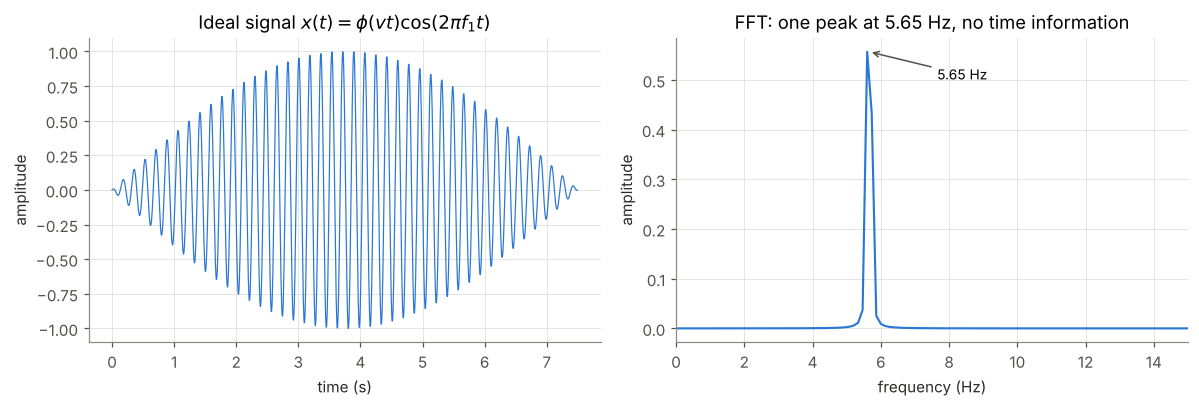

In [9]:
t_ideal, pos_ideal, x_ideal, _ = crossing_signal()
phi_1 = mode_shape(pos_ideal, 1)

freqs_ideal, amp_ideal = spectrum(x_ideal, FS)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t_ideal, x_ideal, color=COLOR_1, linewidth=0.8)
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("amplitude")
axes[0].set_title("Ideal signal $x(t) = \\phi(vt)\\cos(2\\pi f_1 t)$")

axes[1].plot(freqs_ideal, amp_ideal, color=COLOR_1)
axes[1].set_xlim(0, 15)
axes[1].set_xlabel("frequency (Hz)")
axes[1].set_ylabel("amplitude")
axes[1].set_title("FFT: one peak at 5.65 Hz, no time information")
axes[1].annotate(f"{F1} Hz", xy=(F1, amp_ideal.max()), xytext=(F1 + 2, amp_ideal.max() * 0.9),
                 arrowprops=dict(arrowstyle="->", color="#52514e"), fontsize=9)
fig.tight_layout()
plt.show()

**Interpretación.** En el tiempo se ve claramente que la amplitud crece y luego decrece (la forma modal). La FFT solo muestra un pico en 5.65 Hz: sabe *qué* frecuencia hay, pero no *cuándo* la amplitud es grande o pequeña. Se necesita una herramienta que dé **la amplitud en cada instante**.

<a id="hilbert-paso-2"></a>
### Paso 2. La idea: una copia desfasada 90°

Si se mira la señal en un instante cualquiera, su valor depende de dos cosas: la amplitud y en qué punto del ciclo está (si pasa por cero, el valor es cero aunque la amplitud sea grande). La idea es generar una **copia de la señal desfasada 90°**: donde una pasa por cero, la otra está en su máximo. Con las dos juntas, siempre hay información de la amplitud.

Esa copia es la **transformada de Hilbert**:

$$
\mathcal{H}[x(t)] = \frac{1}{\pi}\,\text{p.v.}\int_{-\infty}^{\infty} \frac{x(\tau)}{t-\tau}\,d\tau
$$

- $\mathcal{H}[x(t)]$: transformada de Hilbert de $x$ (la copia desfasada 90°).
- $x(\tau)$: señal evaluada en el instante de integración $\tau$.
- $\tau$: variable de integración (recorre todos los instantes de la señal).
- $t$: instante en el que se evalúa la transformada.
- $\text{p.v.}$: **valor principal de Cauchy**. En $\tau = t$ el denominador es cero; la integral se calcula excluyendo un intervalo simétrico $(t-\varepsilon,\ t+\varepsilon)$ alrededor de ese punto y tomando el límite $\varepsilon \to 0$.

En palabras: es la convolución de la señal con $1/(\pi t)$. Desfasa cada componente de frecuencia 90° sin cambiar su amplitud: $\mathcal{H}[\cos(\omega t)] = \sin(\omega t)$.

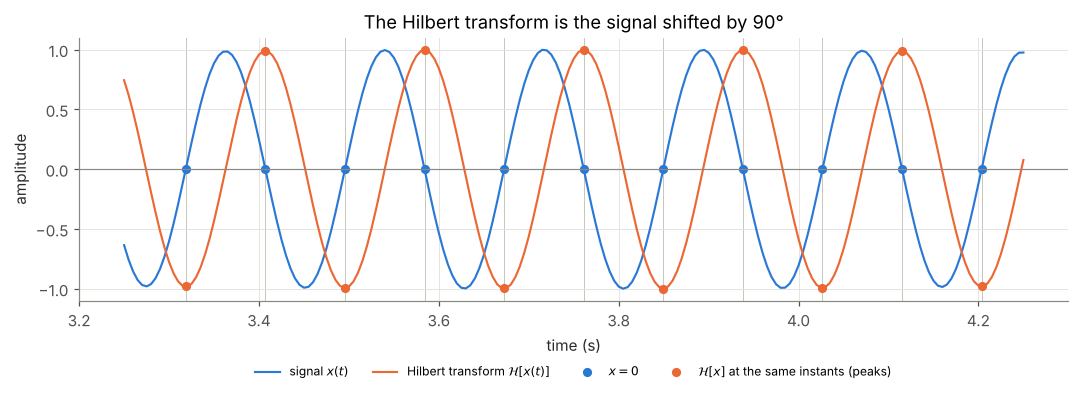

In [10]:
hilbert_ideal = np.imag(hilbert(x_ideal))     # H[x(t)]

segment = (t_ideal >= 3.25) & (t_ideal <= 4.25)   # ~1 s around midspan
ts, xs, hs = t_ideal[segment], x_ideal[segment], hilbert_ideal[segment]
# Zero crossings of x(t), linearly interpolated between samples
zero_idx = np.where(np.diff(np.sign(xs)) != 0)[0]
t_zero = ts[zero_idx] - xs[zero_idx] * (ts[zero_idx + 1] - ts[zero_idx]) / (xs[zero_idx + 1] - xs[zero_idx])
h_at_zero = np.interp(t_zero, ts, hs)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ts, xs, color=COLOR_1, label="signal $x(t)$")
ax.plot(ts, hs, color=COLOR_2, label=r"Hilbert transform $\mathcal{H}[x(t)]$")
ax.plot(t_zero, np.zeros_like(t_zero), "o", ms=5, color=COLOR_1, label="$x = 0$")
ax.plot(t_zero, h_at_zero, "o", ms=5, color=COLOR_2,
        label=r"$\mathcal{H}[x]$ at the same instants (peaks)")
for ti in t_zero:
    ax.axvline(ti, color="#c3c2b7", linewidth=0.6, zorder=0)
ax.axhline(0, color="#8a8984", linewidth=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("amplitude")
ax.set_title("The Hilbert transform is the signal shifted by 90°")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** Cada línea vertical es un cruce por cero de la señal (azul): justo ahí la transformada de Hilbert (naranja) está en un máximo o un mínimo. Las dos curvas nunca son cero a la vez, así que juntas siempre "ven" la amplitud.

<details>
<summary><b>Opcional: cómo se calcula en la práctica (con la FFT)</b></summary>

La integral no se evalúa directamente. En el dominio de la frecuencia, la transformada de Hilbert multiplica cada frecuencia por $-j\,\text{sgn}(f)$: las frecuencias positivas se retrasan 90° y las negativas se adelantan 90°. Eso permite construir directamente la señal analítica $z(t) = x(t) + j\,\mathcal{H}[x(t)]$ (paso 3):

1. Se calcula la FFT de la señal, $X(f)$.
2. Se **anulan** las frecuencias negativas.
3. Se **duplican** las positivas (la componente de 0 Hz y la de Nyquist se dejan igual).
4. La FFT inversa da $z(t)$: su parte real es $x(t)$ y su parte imaginaria es $\mathcal{H}[x(t)]$.

Esto es lo que hace `scipy.signal.hilbert`. Como usa la FFT, supone que la señal es **periódica** (que el final se une con el principio), y de ahí vienen los efectos de borde (paso 4). La celda siguiente implementa estos pasos y verifica que el resultado coincide con `scipy`.
</details>

In [11]:
def hilbert_fft(x):
    # Analytic signal via FFT: zero negative frequencies, double positive ones
    n = x.size
    weights = np.zeros(n)
    weights[0] = 1                                  # DC unchanged
    weights[1:(n + 1) // 2] = 2                     # positive frequencies doubled
    if n % 2 == 0:
        weights[n // 2] = 1                         # Nyquist unchanged
    return np.fft.ifft(np.fft.fft(x) * weights)     # z(t) = x + j H[x]


z_manual = hilbert_fft(x_ideal)
print("Manual FFT implementation matches scipy.signal.hilbert:",
      np.allclose(z_manual, hilbert(x_ideal)))

Manual FFT implementation matches scipy.signal.hilbert: True


<a id="hilbert-paso-3"></a>
### Paso 3. Señal analítica y amplitud instantánea

Se combinan la señal y su copia desfasada en un número complejo, la **señal analítica**:

$$
z(t) = x(t) + j\,\mathcal{H}[x(t)] = A(t)\,e^{j\theta(t)}
$$

- $z(t)$: señal analítica (compleja).
- $x(t)$: señal original (parte real).
- $\mathcal{H}[x(t)]$: transformada de Hilbert (parte imaginaria).
- $j$: unidad imaginaria, $j = \sqrt{-1}$.
- $A(t)$: amplitud instantánea (módulo de $z$).
- $\theta(t)$: fase instantánea (ángulo de $z$).

En palabras: $z(t)$ es un vector que gira en el plano complejo; su longitud es la amplitud y su ángulo indica en qué punto del ciclo está la oscilación.

La amplitud instantánea es el módulo:

$$
A(t) = \sqrt{x(t)^2 + \mathcal{H}[x(t)]^2}
$$

- $A(t)$: amplitud instantánea o envolvente.
- $x(t)$, $\mathcal{H}[x(t)]$: señal y su transformada de Hilbert.

En palabras: la amplitud es la raíz de la señal al cuadrado más su versión desfasada al cuadrado.

**Ejemplo.** Para $x = a\cos(\omega t)$, $\mathcal{H}[x] = a\sin(\omega t)$ y

$$
A = \sqrt{a^2\cos^2(\omega t) + a^2\sin^2(\omega t)} = a\sqrt{\cos^2(\omega t) + \sin^2(\omega t)} = a
$$

Las subidas y bajadas del ciclo se cancelan y queda la amplitud $a$, constante.

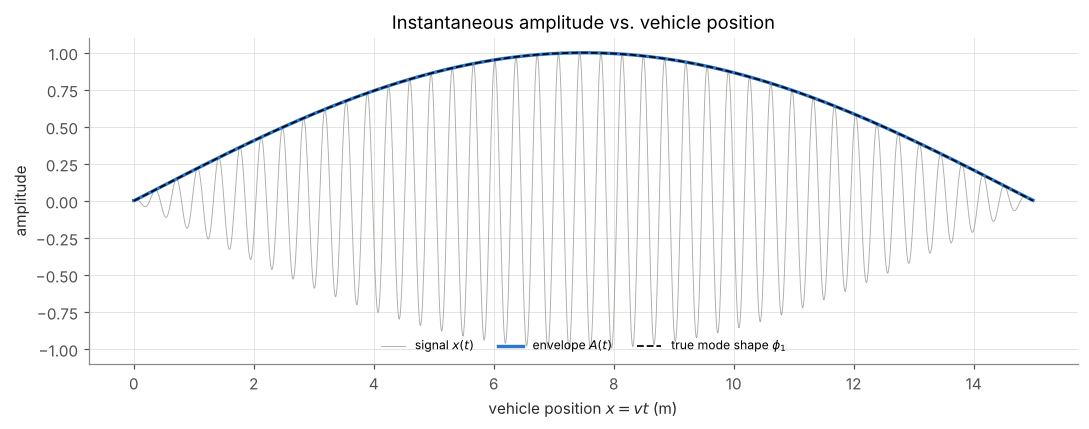

MAC(envelope, phi_1) = 1.0000


In [12]:
env_ideal = envelope(x_ideal)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pos_ideal, x_ideal, color=COLOR_SIGNAL, linewidth=0.6, alpha=0.7, label="signal $x(t)$")
ax.plot(pos_ideal, env_ideal, color=COLOR_1, linewidth=2.2, label="envelope $A(t)$")
ax.plot(pos_ideal, phi_1, "--", color=COLOR_TRUE, linewidth=1.2, label=r"true mode shape $\phi_1$")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("amplitude")
ax.set_title("Instantaneous amplitude vs. vehicle position")
ax.legend(loc="lower center", fontsize=8, ncol=3)
fig.tight_layout()
plt.show()

print(f"MAC(envelope, phi_1) = {mac(trim_edges(env_ideal), trim_edges(phi_1)):.4f}")

**Interpretación.** Al graficar la envolvente contra la posición del vehículo ($x = vt$), reproduce la forma modal: la curva azul queda sobre la forma modal real (línea discontinua).

<a id="hilbert-paso-4"></a>
### Paso 4. Frecuencia instantánea

El ángulo de la señal analítica es la **fase instantánea**, y su derivada da la **frecuencia instantánea**:

$$
\theta(t) = \arctan\frac{\mathcal{H}[x(t)]}{x(t)}, \qquad f(t) = \frac{1}{2\pi}\frac{d\theta(t)}{dt}
$$

- $\theta(t)$: fase instantánea (rad). En el código se calcula con el arcotangente de cuatro cuadrantes (`np.angle`) y se **desenrolla** con `np.unwrap` para quitar los saltos de $2\pi$.
- $\mathcal{H}[x(t)]$, $x(t)$: partes imaginaria y real de $z(t)$.
- $\frac{d\theta}{dt}$: velocidad con la que avanza la fase (rad/s).
- $f(t)$: frecuencia instantánea (Hz); el factor $2\pi$ convierte rad/s en Hz.

En palabras: la frecuencia es qué tan rápido avanza la fase. Si avanza un ciclo ($2\pi$) cada 0.177 s, la frecuencia es 5.65 Hz.

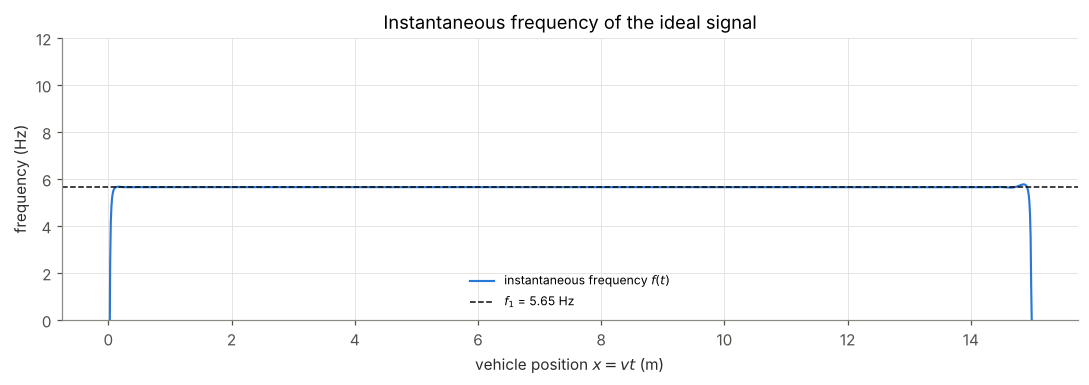

Median f(t), central 80 %: 5.650 Hz


In [13]:
freq_ideal = inst_freq(x_ideal, FS)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(pos_ideal, freq_ideal, color=COLOR_1, label="instantaneous frequency $f(t)$")
ax.axhline(F1, linestyle="--", color=COLOR_TRUE, linewidth=1, label=f"$f_1$ = {F1} Hz")
ax.set_ylim(0, 12)
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("frequency (Hz)")
ax.set_title("Instantaneous frequency of the ideal signal")
ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
plt.show()

print(f"Median f(t), central 80 %: {np.median(trim_edges(freq_ideal)):.3f} Hz")

**Interpretación.** La frecuencia instantánea es constante e igual a 5.65 Hz en casi todo el cruce y solo se desvía en los extremos.

<div style="border-left: 4px solid #eb6834; background: rgba(235, 104, 52, 0.08); padding: 8px 12px; margin: 8px 0;">

⚠️ **Advertencia: efecto de borde.** Los extremos se distorsionan porque el cálculo con la FFT supone que la señal es periódica (que el final se une con el principio). Además, en este caso la amplitud tiende a cero en los apoyos, y donde la amplitud es casi cero la fase está mal definida. Los primeros y últimos ciclos no deben interpretarse: en este notebook se descarta el 10 % de cada extremo (`trim_edges`).
</div>

<a id="hilbert-paso-5"></a>
### Paso 5. ¿Solo funciona con senoidales?

No hace falta una senoidal pura: la amplitud puede variar de cualquier forma, **siempre que cambie mucho más lento que la oscilación**. La condición formal es el **teorema de Bedrosian**:

$$
\mathcal{H}[a(t)\cos(2\pi f_0 t)] = a(t)\sin(2\pi f_0 t) \quad \text{si el espectro de } a(t) \text{ está por debajo de } f_0
$$

- $a(t)$: amplitud lenta (la envolvente que se quiere recuperar).
- $f_0$: frecuencia de la oscilación (portadora).
- $\cos(2\pi f_0 t)$, $\sin(2\pi f_0 t)$: la oscilación y su versión desfasada 90°.

En palabras: la transformada de Hilbert "atraviesa" la amplitud y solo desfasa la oscilación, de modo que la envolvente $A(t) = |a(t)|$ se recupera exactamente, siempre que los espectros de la amplitud y de la oscilación no se superpongan.

A continuación, varias formas de envolvente con $f_0 = f_1 = 5.65$ Hz: tres que cumplen la condición y una que no (amplitud que oscila a 7 Hz, más rápido que la propia oscilación).

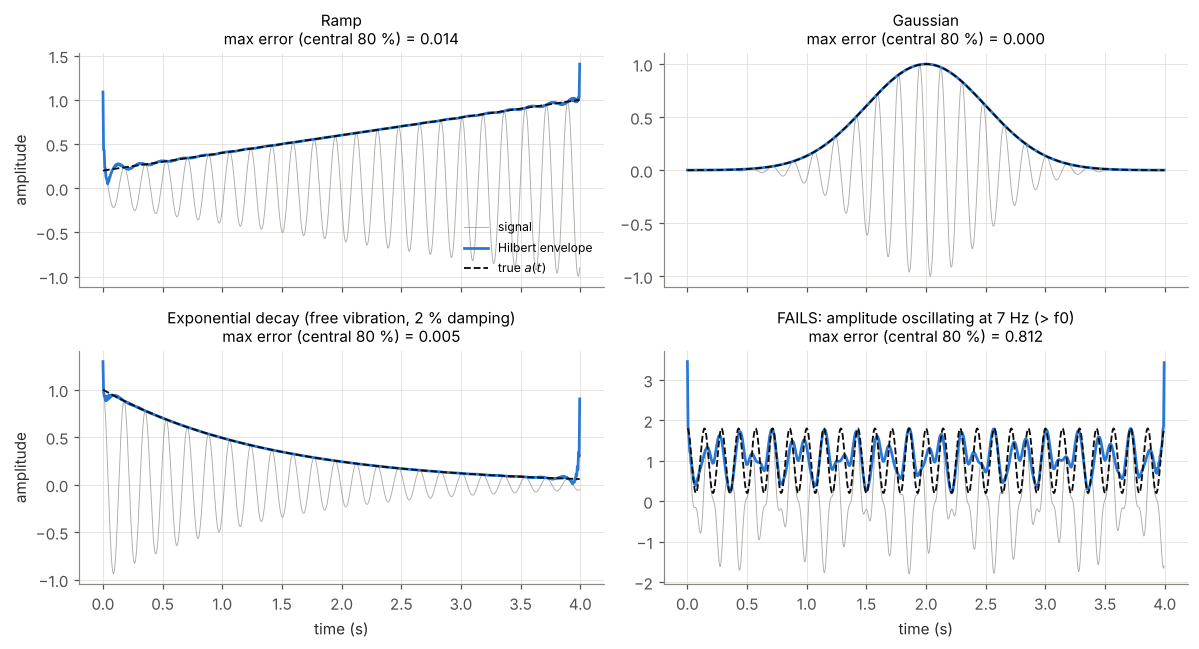

In [14]:
t_b = np.arange(0, 4, 1 / FS)
carrier = np.cos(2 * np.pi * F1 * t_b)

amplitude_cases = {
    "Ramp": 0.2 + 0.8 * t_b / t_b[-1],
    "Gaussian": np.exp(-0.5 * ((t_b - 2) / 0.5) ** 2),
    "Exponential decay (free vibration, 2 % damping)": np.exp(-0.02 * 2 * np.pi * F1 * t_b),
    "FAILS: amplitude oscillating at 7 Hz (> f0)": 1 + 0.8 * np.cos(2 * np.pi * 7.0 * t_b),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, (name, a_true) in zip(axes.flat, amplitude_cases.items()):
    x_b = a_true * carrier
    ax.plot(t_b, x_b, color=COLOR_SIGNAL, linewidth=0.6, alpha=0.7, label="signal")
    ax.plot(t_b, envelope(x_b), color=COLOR_1, linewidth=1.8, label="Hilbert envelope")
    ax.plot(t_b, a_true, "--", color=COLOR_TRUE, linewidth=1.2, label="true $a(t)$")
    err = np.max(np.abs(trim_edges(envelope(x_b) - a_true)))
    ax.set_title(f"{name}\nmax error (central 80 %) = {err:.3f}", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("amplitude")
axes[0, 0].legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** La rampa, la gaussiana y el decaimiento exponencial (como una vibración libre amortiguada) se recuperan casi exactamente: su espectro está muy por debajo de 5.65 Hz. Las pequeñas desviaciones están solo en los bordes (en la rampa y el decaimiento, la señal no "empieza ni termina" de forma suave). En el último caso la amplitud cambia más rápido que la oscilación: los espectros se superponen, la condición de Bedrosian no se cumple y la "envolvente" ya no sigue a $a(t)$.

<a id="hilbert-paso-6"></a>
### Paso 6. El caso que lo rompe: varias frecuencias mezcladas

Una señal real medida en un vehículo que cruza un puente **no es monocomponente**. Contiene a la vez:

- la respuesta de **varios modos** del puente;
- la **dinámica propia del vehículo** (rebote de la carrocería, frecuencia de los ejes);
- la **rugosidad de la carretera**, de banda ancha;
- el **ruido del sensor**.

Se construye una señal realista con la misma función `crossing_signal`:

| Componente | Frecuencia | Amplitud |
|---|---|---|
| Modo 1, $\sin(\pi x/L)$ | 5.65 Hz | 1.0 |
| Modo 2, $\sin(2\pi x/L)$ | 22.62 Hz | 0.5 |
| Rebote del vehículo | ~2 Hz | 0.8 (casi constante) |
| Rugosidad | banda ancha, 0–30 Hz | desv. estándar 0.3 |
| Ruido del sensor | blanco | desv. estándar 0.1 |

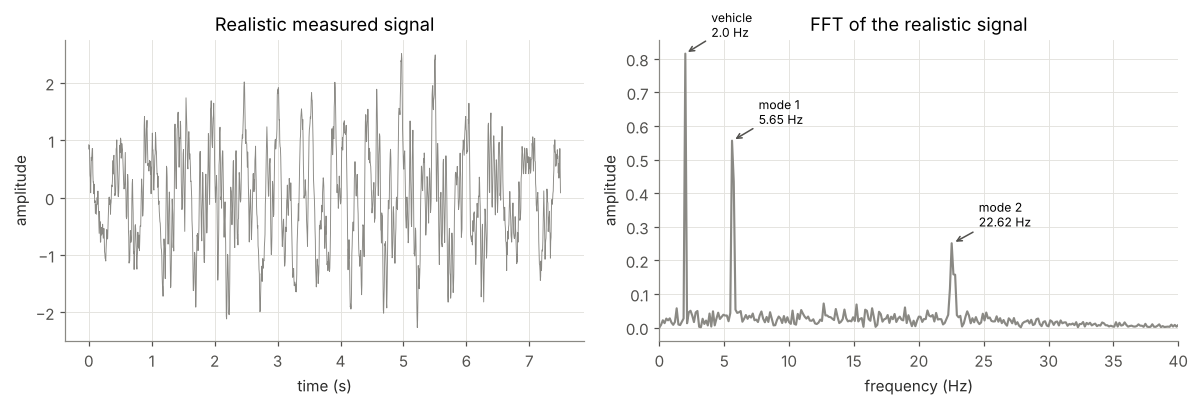

In [15]:
REALISTIC = dict(mode_amps=(1.0, 0.5), vehicle_amp=0.8, roughness_amp=0.3, noise_std=0.1)

t_r, pos_r, x_real, parts_real = crossing_signal(**REALISTIC)
x_real = detrend(x_real)                 # remove mean and linear trend
freqs_r, amp_r = spectrum(x_real, FS)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t_r, x_real, color=COLOR_SIGNAL, linewidth=0.6)
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("amplitude")
axes[0].set_title("Realistic measured signal")

axes[1].plot(freqs_r, amp_r, color=COLOR_SIGNAL)
axes[1].set_xlim(0, 40)
axes[1].set_xlabel("frequency (Hz)")
axes[1].set_ylabel("amplitude")
axes[1].set_title("FFT of the realistic signal")
for f, label in [(F_VEHICLE, "vehicle"), (F1, "mode 1"), (F2, "mode 2")]:
    k = np.argmin(np.abs(freqs_r - f))
    peak = amp_r[max(k - 3, 0):k + 4].max()
    axes[1].annotate(f"{label}\n{f} Hz", xy=(f, peak), xytext=(f + 2, peak + 0.05),
                     arrowprops=dict(arrowstyle="->", color="#52514e"), fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** La FFT muestra los picos del vehículo (~2 Hz), del modo 1 (5.65 Hz) y del modo 2 (22.62 Hz), sobre un fondo de banda ancha (rugosidad y ruido). Ahora se aplica Hilbert **directamente** a esta señal:

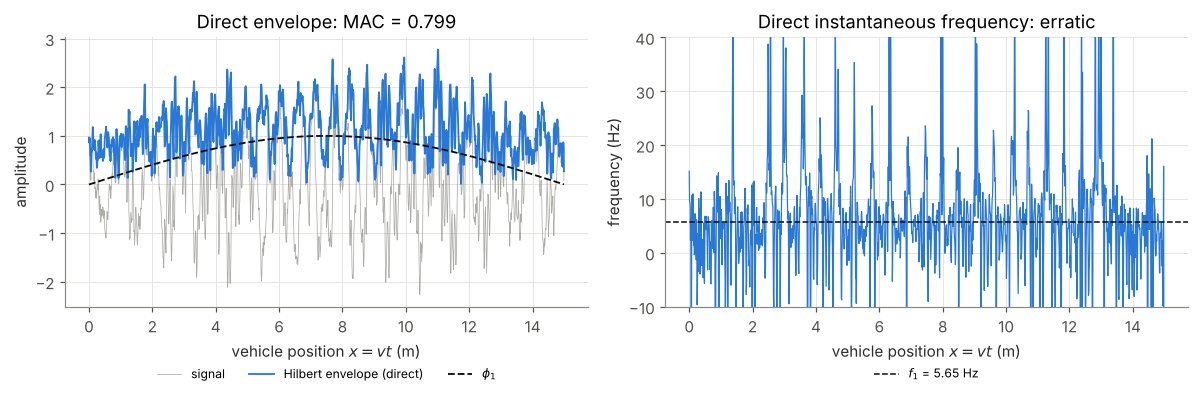

MAC (direct Hilbert vs phi_1, central 80 %) = 0.799


In [16]:
env_direct = envelope(x_real)
freq_direct = inst_freq(x_real, FS)
mac_direct = mac(trim_edges(env_direct), trim_edges(phi_1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(pos_r, x_real, color=COLOR_SIGNAL, linewidth=0.5, alpha=0.7, label="signal")
axes[0].plot(pos_r, env_direct, color=COLOR_1, linewidth=1.2, label="Hilbert envelope (direct)")
axes[0].plot(pos_r, phi_1, "--", color=COLOR_TRUE, linewidth=1.2, label=r"$\phi_1$")
axes[0].set_xlabel("vehicle position $x = vt$ (m)")
axes[0].set_ylabel("amplitude")
axes[0].set_title(f"Direct envelope: MAC = {mac_direct:.3f}")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)

axes[1].plot(pos_r, freq_direct, color=COLOR_1, linewidth=0.8)
axes[1].axhline(F1, linestyle="--", color=COLOR_TRUE, linewidth=1, label=f"$f_1$ = {F1} Hz")
axes[1].set_ylim(-10, 40)
axes[1].set_xlabel("vehicle position $x = vt$ (m)")
axes[1].set_ylabel("frequency (Hz)")
axes[1].set_title("Direct instantaneous frequency: erratic")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8)
fig.tight_layout()
plt.show()

print(f"MAC (direct Hilbert vs phi_1, central 80 %) = {mac_direct:.3f}")

**Interpretación.** Las componentes se suman y se restan entre sí (batido), así que la envolvente sale **ondulada**, no sigue la forma modal y no tiene significado físico; la frecuencia instantánea salta de forma errática en lugar de quedarse en 5.65 Hz. El MAC con la forma modal es 0.799, por debajo de 0.9.

<a id="hilbert-paso-7"></a>
### Paso 7. Requisitos previos: preparar la señal

<div style="border: 2px solid #2a78d6; border-radius: 6px; padding: 10px 14px; margin: 8px 0;">

📋 **Requisitos de la señal antes de aplicar Hilbert**

1. **Aislar una sola componente** (requisito principal): filtrar o descomponer para quedarse con una frecuencia dominante.
2. **Quitar la media y la tendencia** (`scipy.signal.detrend`): un desplazamiento constante se suma a la envolvente.
3. **Suficientes ciclos** dentro del registro (frecuencia × duración grande): con pocos ciclos, los bordes ocupan todo el registro.
4. **Muestreo adecuado:** $f_s$ bastante mayor que el doble de la frecuencia de interés.
5. **Manejar los bordes:** descartar los extremos, *padding* por reflexión o ventana suave.
6. **Reducir el ruido**, que pasa directo a la amplitud (y, amplificado, a la frecuencia instantánea).
</div>

Hay dos formas habituales de aislar la componente del modo.

#### 7a. Filtro pasabanda + Hilbert

Si se conoce la frecuencia de interés, se filtra la señal con un **pasabanda** alrededor de ella (aquí 4.5–7 Hz, Butterworth de orden 4 aplicado hacia adelante y hacia atrás con `sosfiltfilt`, para no desfasar la señal) y luego se aplica Hilbert.

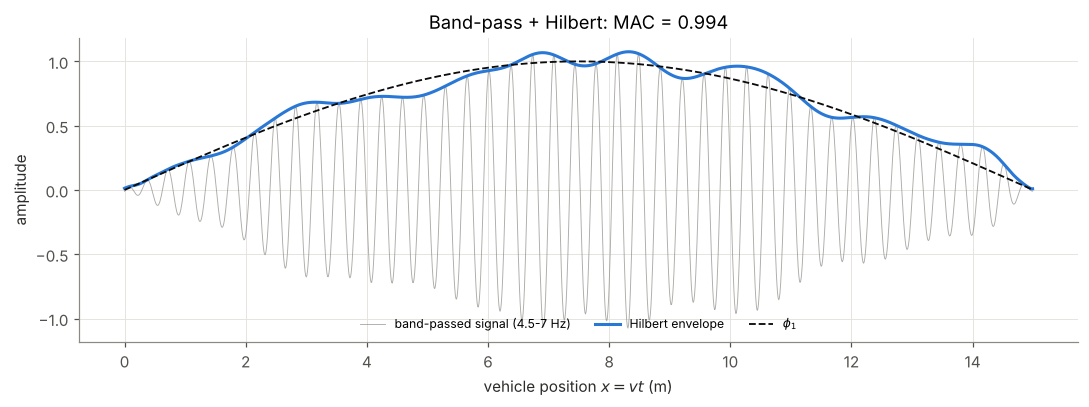

In [17]:
x_bp = bandpass(x_real, FS, 4.5, 7.0)
env_bp = envelope(x_bp)
freq_bp = inst_freq(x_bp, FS)
mac_bp = mac(trim_edges(env_bp), trim_edges(phi_1))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(pos_r, x_bp, color=COLOR_SIGNAL, linewidth=0.6, alpha=0.7, label="band-passed signal (4.5-7 Hz)")
ax.plot(pos_r, env_bp, color=COLOR_1, linewidth=2, label="Hilbert envelope")
ax.plot(pos_r, phi_1, "--", color=COLOR_TRUE, linewidth=1.2, label=r"$\phi_1$")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("amplitude")
ax.set_title(f"Band-pass + Hilbert: MAC = {mac_bp:.3f}")
ax.legend(loc="lower center", ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** Después del pasabanda, la señal es casi monocomponente y la envolvente sigue la forma modal. Las pequeñas ondulaciones que quedan vienen de la rugosidad y el ruido que caen dentro de la banda 4.5–7 Hz: el filtro no puede quitarlos.

#### 7b. EMD + Hilbert (transformada de Hilbert-Huang, HHT)

Si no se quiere fijar la banda de antemano, se descompone la señal con **EMD** (sección [1.1](#emd)) en IMF y se aplica Hilbert a la IMF cuya frecuencia dominante esté más cerca de 5.65 Hz.

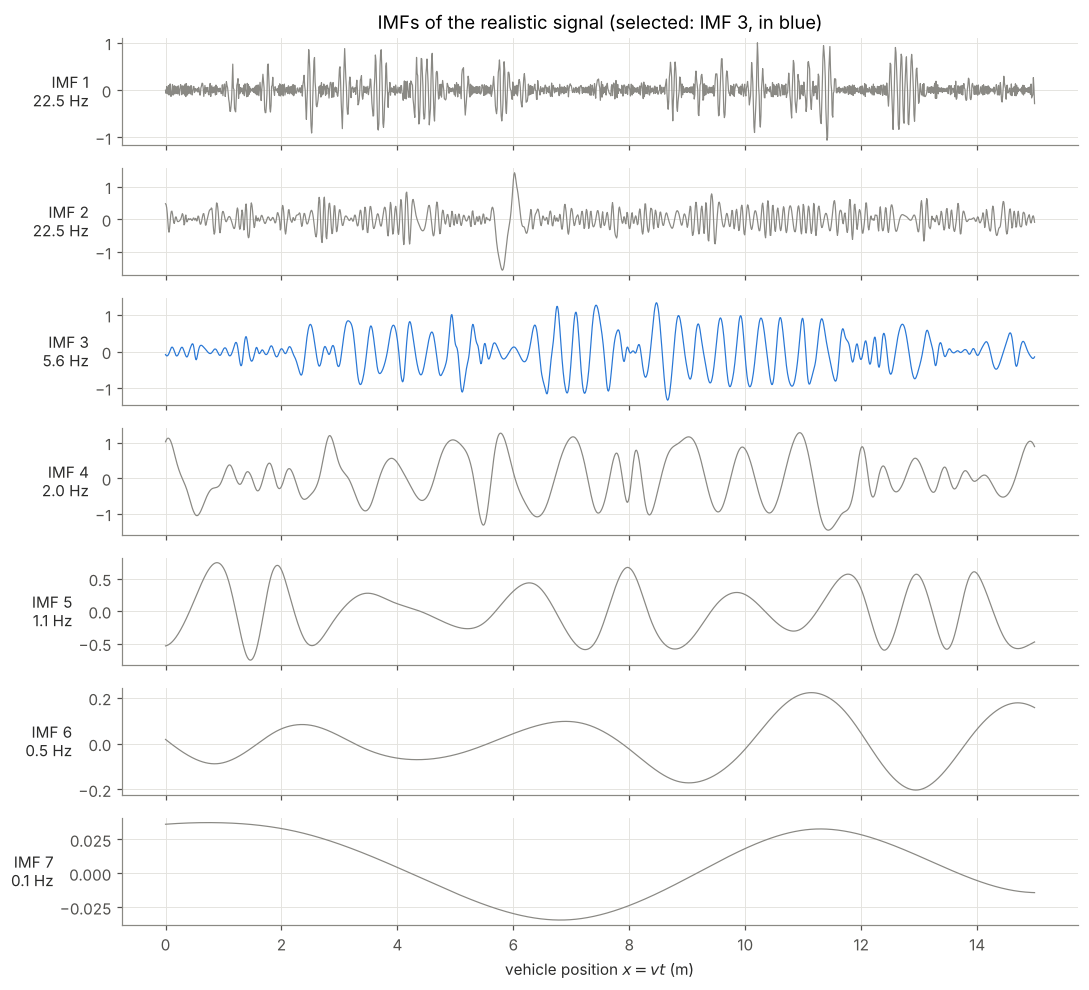

In [18]:
emd_real = EMD()
emd_real.emd(x_real, t_r)
imfs_real, residue_real = emd_real.get_imfs_and_residue()
imf_dom_freqs = np.array([dominant_frequency(imf, FS) for imf in imfs_real])
k_mode_1 = np.argmin(np.abs(imf_dom_freqs - F1))     # IMF closest to f1

n_imfs_real = imfs_real.shape[0]
fig, axes = plt.subplots(n_imfs_real, 1, figsize=(10, 1.3 * n_imfs_real), sharex=True)
for i, (ax, imf) in enumerate(zip(axes, imfs_real)):
    color = COLOR_1 if i == k_mode_1 else COLOR_SIGNAL
    ax.plot(pos_r, imf, color=color, linewidth=0.8)
    ax.set_ylabel(f"IMF {i + 1}\n{imf_dom_freqs[i]:.1f} Hz", rotation=0, ha="right", va="center")
axes[0].set_title(f"IMFs of the realistic signal (selected: IMF {k_mode_1 + 1}, in blue)")
axes[-1].set_xlabel("vehicle position $x = vt$ (m)")
fig.tight_layout()
plt.show()

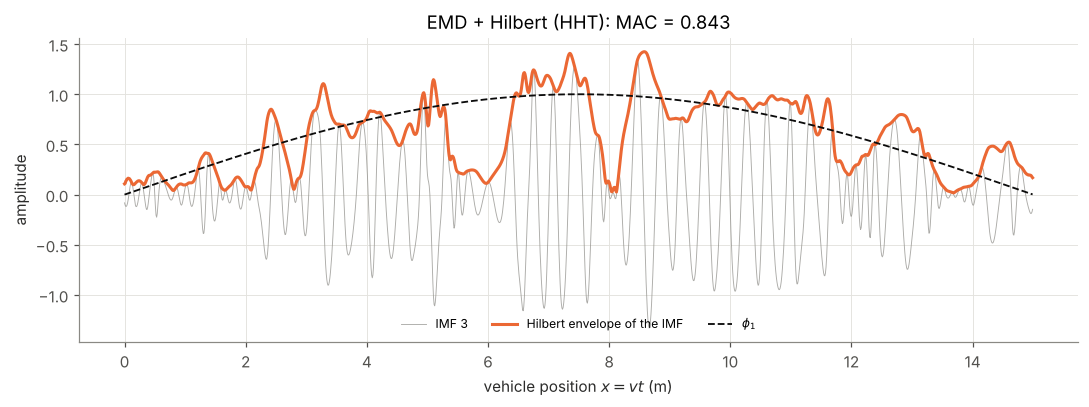

In [19]:
imf_mode_1 = imfs_real[k_mode_1]
env_emd = envelope(imf_mode_1)
freq_emd = inst_freq(imf_mode_1, FS)
mac_emd = mac(trim_edges(env_emd), trim_edges(phi_1))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(pos_r, imf_mode_1, color=COLOR_SIGNAL, linewidth=0.6, alpha=0.7, label=f"IMF {k_mode_1 + 1}")
ax.plot(pos_r, env_emd, color=COLOR_2, linewidth=2, label="Hilbert envelope of the IMF")
ax.plot(pos_r, phi_1, "--", color=COLOR_TRUE, linewidth=1.2, label=r"$\phi_1$")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("amplitude")
ax.set_title(f"EMD + Hilbert (HHT): MAC = {mac_emd:.3f}")
ax.legend(loc="lower center", ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** En este ejemplo la EMD **no** aísla bien el modo 1. La IMF 3 tiene la frecuencia dominante correcta (5.6 Hz), pero en varios tramos se mezcla con el rebote del vehículo (~2 Hz, que en la IMF 4 aparece también mezclado) y con la rugosidad, sobre todo donde la amplitud del modo es pequeña (cerca de los apoyos). La envolvente sigue la tendencia general de la forma modal, pero con grandes oscilaciones (MAC = 0.843). Es la **mezcla de modos** en acción.

> ⚠️ **Riesgo: mezcla de modos.** Si dos componentes tienen frecuencias cercanas (por ejemplo, el rebote del vehículo y un modo del puente) o hay mucho ruido, la EMD puede poner las dos en la misma IMF o repartir una componente entre dos IMF. Entonces la envolvente vuelve a quedar contaminada. Ver la sección [1.1](#emd), gráfica (d).

Comparación de la frecuencia instantánea en los tres casos:

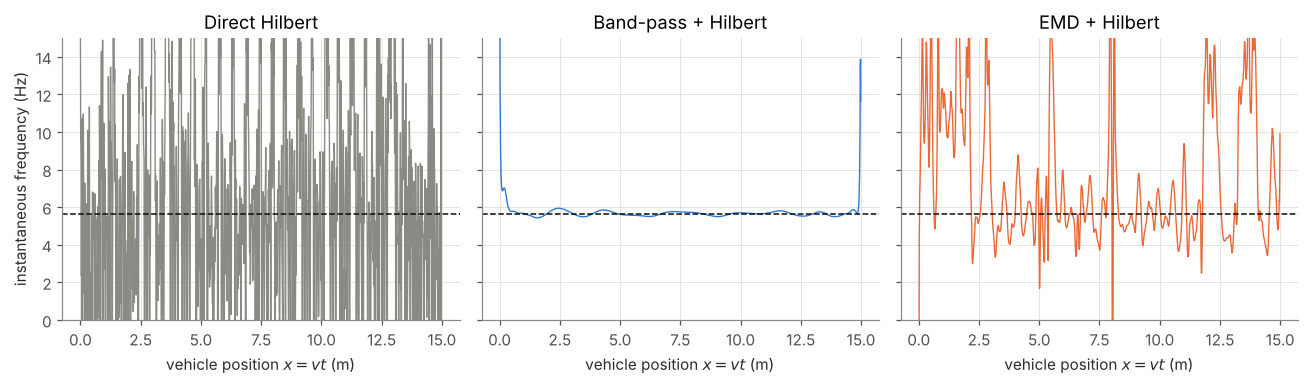

| Case | MAC (central 80 %) |
|---|---|
| Direct Hilbert | 0.799 |
| Band-pass + Hilbert | 0.994 |
| EMD + Hilbert | 0.843 |


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, freq, color, title in [
    (axes[0], freq_direct, COLOR_SIGNAL, "Direct Hilbert"),
    (axes[1], freq_bp, COLOR_1, "Band-pass + Hilbert"),
    (axes[2], freq_emd, COLOR_2, "EMD + Hilbert"),
]:
    ax.plot(pos_r, freq, color=color, linewidth=0.9)
    ax.axhline(F1, linestyle="--", color=COLOR_TRUE, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("vehicle position $x = vt$ (m)")
axes[0].set_ylim(0, 15)
axes[0].set_ylabel("instantaneous frequency (Hz)")
fig.tight_layout()
plt.show()

print("| Case | MAC (central 80 %) |")
print("|---|---|")
for name, value in [("Direct Hilbert", mac_direct), ("Band-pass + Hilbert", mac_bp),
                    ("EMD + Hilbert", mac_emd)]:
    print(f"| {name} | {value:.3f} |")

**Interpretación.** Sin preparar la señal, la frecuencia instantánea es errática; con pasabanda o EMD queda estable cerca de 5.65 Hz (salvo en los bordes).

El **MAC** (*Modal Assurance Criterion*) mide qué tan parecidas son dos formas modales:

$$
\text{MAC} = \frac{\left|\boldsymbol{\phi}_{e}^{T}\,\boldsymbol{\phi}_{r}\right|^{2}}{\left(\boldsymbol{\phi}_{e}^{T}\boldsymbol{\phi}_{e}\right)\left(\boldsymbol{\phi}_{r}^{T}\boldsymbol{\phi}_{r}\right)}
$$

- $\boldsymbol{\phi}_e$: forma estimada (vector con la envolvente en cada punto).
- $\boldsymbol{\phi}_r$: forma de referencia (la forma modal real).
- $T$: transpuesta ($\boldsymbol{a}^T\boldsymbol{b}$ es el producto punto).

En palabras: es el coseno al cuadrado del ángulo entre los dos vectores. Vale entre 0 y 1; 1 significa la misma forma (sin importar la escala) y un valor mayor que 0.9 se considera buena coincidencia.

MAC calculado descartando el 10 % de cada extremo:

| Caso | MAC |
|---|---|
| Hilbert directo | 0.799 |
| Pasabanda + Hilbert | 0.994 |
| EMD + Hilbert | 0.843 |

Con el pasabanda, el MAC sube de 0.80 a 0.99. La EMD mejora poco (0.84) por la mezcla de modos: en este ejemplo, como la frecuencia del modo se conoce, el pasabanda funciona mejor. Observa también que el MAC es tolerante: una envolvente visiblemente ondulada todavía puede dar 0.8–0.9, así que conviene mirar la gráfica además del número.

<a id="hilbert-paso-8"></a>
### Paso 8. Aplicación a un puente: de la amplitud a la forma modal

Flujo completo:

**medir** la respuesta del vehículo → **quitar media y tendencia** → **aislar** la componente del modo (pasabanda o EMD) → **Hilbert** → **amplitud instantánea** $A(t)$ → **convertir tiempo en posición** ($x = vt$) → **forma modal**.

#### Pérdida de signo

La amplitud instantánea siempre es positiva. Con el segundo modo, que cambia de signo a mitad del vano, la envolvente da $|\phi_2|$, no $\phi_2$: no se distingue qué lado sube y cuál baja.

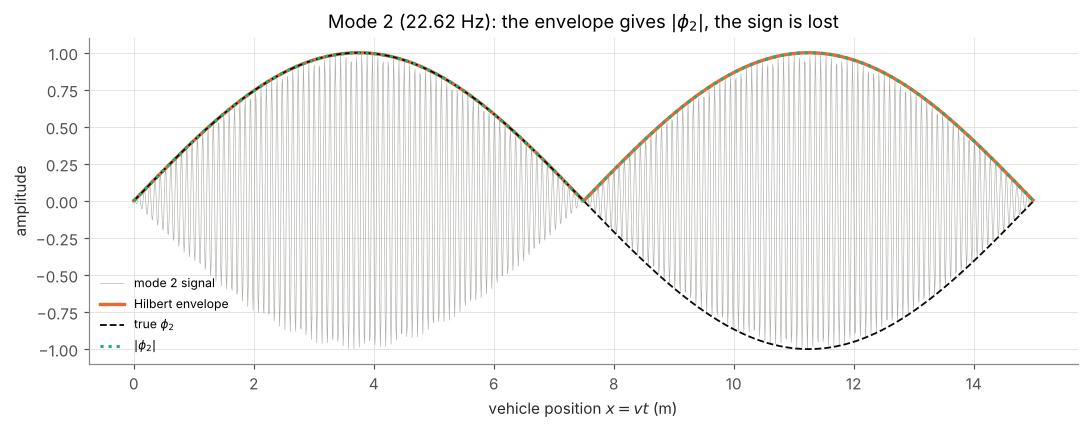

In [21]:
t_m2, pos_m2, x_mode_2, _ = crossing_signal(mode_amps=(0.0, 1.0))
phi_2 = mode_shape(pos_m2, 2)
env_mode_2 = envelope(x_mode_2)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pos_m2, x_mode_2, color=COLOR_SIGNAL, linewidth=0.4, alpha=0.7, label="mode 2 signal")
ax.plot(pos_m2, env_mode_2, color=COLOR_2, linewidth=2.2, label="Hilbert envelope")
ax.plot(pos_m2, phi_2, "--", color=COLOR_TRUE, linewidth=1.2, label=r"true $\phi_2$")
ax.plot(pos_m2, np.abs(phi_2), ":", color=COLOR_3, linewidth=2, label=r"$|\phi_2|$")
ax.set_xlabel("vehicle position $x = vt$ (m)")
ax.set_ylabel("amplitude")
ax.set_title(f"Mode 2 ({F2} Hz): the envelope gives $|\\phi_2|$, the sign is lost")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** La envolvente coincide con $|\phi_2|$: la mitad negativa de la forma modal aparece reflejada hacia arriba. Para recuperar el signo hace falta información adicional (por ejemplo, el salto de 180° de la fase en el nodo, o una referencia).

> 📝 **Nota.** Lo que se obtiene con este procedimiento es una **forma deflectada operacional** (ODS, *operational deflection shape*): la amplitud de la respuesta a la frecuencia del modo durante el cruce. Es una **aproximación** a la forma modal, que se parece a ella cuando ese modo domina la respuesta en la banda analizada.

#### Efecto de la velocidad

Con una velocidad mayor, el cruce dura menos y el número de ciclos del modo dentro del registro, $f_1 L / v$, disminuye. Con pocos ciclos, el filtro y la transformada de Hilbert no tienen "espacio" para estabilizarse y los bordes ocupan casi todo el registro.

El siguiente widget permite cambiar la velocidad, el nivel de ruido y la amplitud del modo 2 (se usa pasabanda 4.5–7 Hz + Hilbert). *GitHub no muestra widgets: debajo hay una gráfica estática equivalente.*

In [22]:
def plot_velocity_case(ax, v, noise_std=REALISTIC["noise_std"], mode2_amp=REALISTIC["mode_amps"][1]):
    # Band-pass + Hilbert envelope for a crossing at speed v
    params = dict(REALISTIC, mode_amps=(1.0, mode2_amp), noise_std=noise_std)
    _, pos_v, x_v, _ = crossing_signal(v=v, **params)
    env_v = envelope(bandpass(detrend(x_v), FS, 4.5, 7.0))
    phi_v = mode_shape(pos_v, 1)
    n_cycles = F1 * L_SPAN / v
    mac_v = mac(trim_edges(env_v), trim_edges(phi_v))
    ax.plot(pos_v, env_v, color=COLOR_1, linewidth=2, label="band-pass + Hilbert envelope")
    ax.plot(pos_v, phi_v, "--", color=COLOR_TRUE, linewidth=1.2, label=r"$\phi_1$")
    ax.set_title(f"v = {v:g} m/s: {n_cycles:.1f} cycles, MAC = {mac_v:.3f}", fontsize=10)
    ax.set_xlabel("vehicle position $x = vt$ (m)")
    return mac_v


def interactive_velocity(v=2.0, noise_std=0.1, mode2_amp=0.5):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    plot_velocity_case(ax, v, noise_std, mode2_amp)
    ax.set_ylabel("amplitude")
    ax.set_ylim(0, 1.6)
    ax.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    plt.show()


widgets.interact(
    interactive_velocity,
    v=widgets.FloatSlider(value=2.0, min=1.0, max=20.0, step=1.0, description="v (m/s)"),
    noise_std=widgets.FloatSlider(value=0.1, min=0.0, max=0.5, step=0.05, description="noise std"),
    mode2_amp=widgets.FloatSlider(value=0.5, min=0.0, max=1.0, step=0.1, description="mode 2 amp"),
);

interactive(children=(FloatSlider(value=2.0, description='v (m/s)', max=20.0, min=1.0, step=1.0), FloatSlider(…

**Gráfica estática equivalente** (v = 2, 5, 10 y 20 m/s; ruido 0.1; amplitud del modo 2 = 0.5):

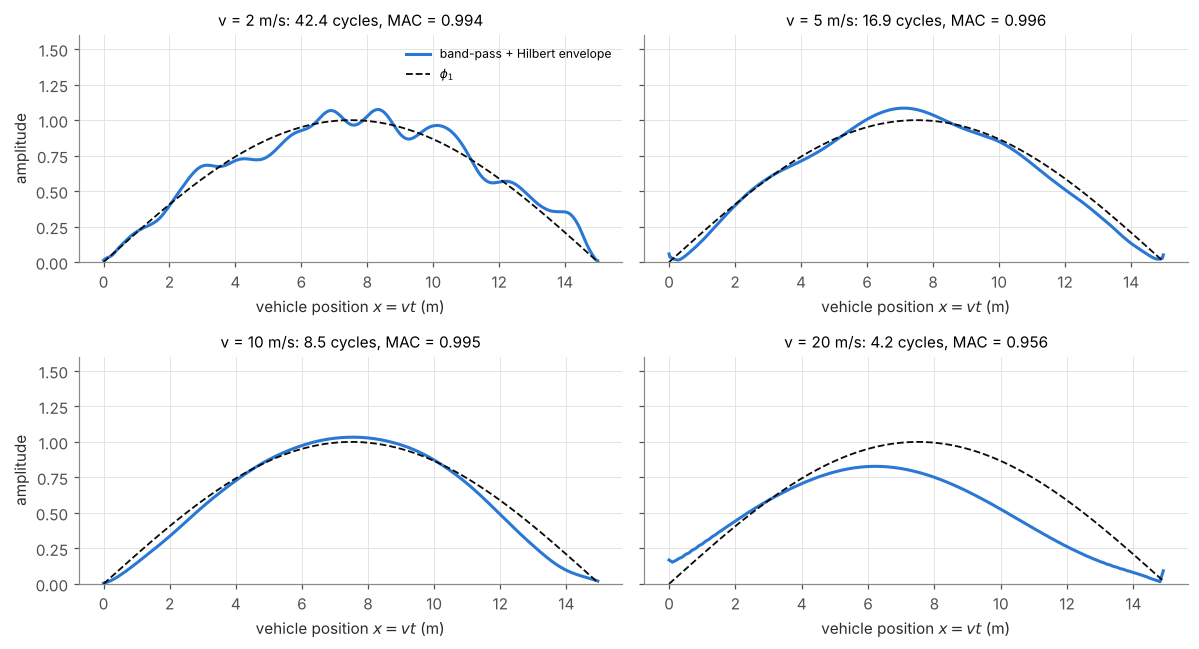

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
velocity_macs = {}
for ax, v in zip(axes.flat, [2, 5, 10, 20]):
    velocity_macs[v] = plot_velocity_case(ax, v)
axes[0, 0].set_ylim(0, 1.6)
for ax in axes[:, 0]:
    ax.set_ylabel("amplitude")
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

**Interpretación.** A 2 m/s (42 ciclos) la envolvente sigue la forma modal, con pequeñas ondulaciones de la rugosidad y el ruido que caen dentro de la banda. A 5 y 10 m/s (17 y 8.5 ciclos) la forma se sigue recuperando bien. A 20 m/s quedan solo ~4 ciclos: la envolvente se deforma y se desplaza hacia el inicio del vano y el MAC baja a 0.956. Aunque el MAC siga por encima de 0.9, la forma ya está visiblemente distorsionada.

> 📝 **Nota sobre el modelo.** Este ejemplo es sintético y simplificado: la rugosidad se genera como ruido en el tiempo (no como un perfil espacial de la carretera) y no hay interacción vehículo-puente. Por eso solo ilustra el efecto del número de ciclos; no reproduce cómo cambian la excitación de la rugosidad ni la respuesta del puente con la velocidad.

#### Cómo lo resuelven Malekjafarian y OBrien (2017)

Los problemas anteriores (otras componentes que contaminan la banda del modo, rugosidad, ruido) son los que aborda el método de Malekjafarian y OBrien (2017):

1. **Excitador en el vehículo:** un excitador montado en el vehículo aplica una fuerza a una frecuencia cercana a la frecuencia natural del puente, de modo que **ese modo domina la respuesta**.
2. **EMD + Hilbert:** aplican EMD a la respuesta medida y la transformada de Hilbert a la IMF del modo, para obtener su amplitud instantánea.
3. **Eliminar la rugosidad:** restan las señales de ejes consecutivos, que pasan por la misma rugosidad, por ejemplo $\ddot{x}_1 = \ddot{y}_6 - \ddot{y}_4$ ($\ddot{y}_i$: aceleración medida en el eje $i$; $\ddot{x}_1$: señal diferencia).
4. **Encadenar tramos:** cada medición cubre un tramo del puente; los tramos se unen y se **reescalan** para formar la forma modal completa.

**Limitaciones reportadas:** precisión pobre con rugosidad clase C; velocidad simulada baja (2 m/s); sensibilidad al ruido y a modos de frecuencias cercanas.

<a id="hilbert-paso-9"></a>
### Paso 9. Síntesis

#### Requisitos previos de la señal

| Requisito | Por qué | Cómo cumplirlo |
|---|---|---|
| Una sola componente | Con varias frecuencias, las componentes se suman y restan y la envolvente pierde significado físico | Filtro pasabanda (si se conoce la frecuencia) o EMD / variantes (EEMD, CEEMDAN) |
| Sin media ni tendencia | Un desplazamiento se suma a la envolvente y distorsiona la fase | `scipy.signal.detrend` |
| Amplitud lenta (Bedrosian) | La envolvente solo se recupera si su espectro está por debajo de la frecuencia de la oscilación | Verificar que la amplitud cambia mucho más lento que la oscilación |
| Suficientes ciclos | Con pocos ciclos, los efectos de borde ocupan todo el registro | Registros largos, velocidades bajas, frecuencias no muy bajas ($f L / v$ grande) |
| Muestreo adecuado | La fase y su derivada necesitan varias muestras por ciclo | $f_s$ bastante mayor que $2f$ |
| Manejo de bordes | El cálculo con FFT supone una señal periódica | Descartar extremos, *padding* por reflexión, ventana suave |
| Poco ruido | El ruido pasa directo a la amplitud y, amplificado por la derivada, a la frecuencia | Filtrado, promediado de varios cruces |

#### Fortalezas y debilidades

| Fortalezas | Debilidades |
|---|---|
| Amplitud y frecuencia **en cada instante**, no promediadas como en la FFT | Solo tiene sentido con señales **monocomponente**; exige filtrado o descomposición previa |
| Apta para señales **no estacionarias**, como un cruce de vehículo | **Efectos de borde** |
| **Rápida y simple** (una FFT y una FFT inversa) | **Muy sensible al ruido** (sobre todo la frecuencia instantánea) |
| No requiere elegir función base ni resolución (a diferencia de wavelets o STFT) | **Pierde el signo** de la forma modal |
| | Pobre con **pocos ciclos** (cruces rápidos o frecuencias bajas) |
| | Si el paso previo falla (modos cercanos, mezcla de modos en EMD), el resultado es incorrecto |

#### Relación con otros métodos

- **EMD + Hilbert = transformada de Hilbert-Huang (HHT).** La EMD (sección [1.1](#emd)) entrega componentes monocomponente y Hilbert les calcula amplitud y frecuencia instantáneas.
- **Pasabanda + Hilbert:** alternativa más simple cuando se conoce la frecuencia de interés.
- **Alternativas para la amplitud instantánea:**
  - **Wavelet continua (CWT):** amplitud tiempo-frecuencia con resolución que depende de la escala; requiere elegir la wavelet madre.
  - **Wavelet sincrosqueezada (SST):** reasigna la energía de la CWT para concentrarla en la frecuencia instantánea; la usan Cronin et al. (2024) para las magnitudes instantáneas en la agregación multiviaje.
  - **STFT** (transformada de Fourier de tiempo corto): requiere elegir el tamaño de la ventana (compromiso entre resolución en tiempo y en frecuencia).

#### Uso en la literatura

- **Malekjafarian, A. y OBrien, E. J. (2017).** On the use of a passing vehicle for the estimation of bridge mode shapes. *Journal of Sound and Vibration*, 397, 77–91. Aplican la HHT (EMD + Hilbert) sobre las aceleraciones de los ejes 6 y 7 de un camión con dos remolques, con un excitador en el eje 4, para estimar las formas modales del puente; validación solo numérica.
- **Yang et al. (2014)**, citado por Malekjafarian y OBrien (2017): filtro pasabanda + transformada de Hilbert para obtener la amplitud de la respuesta a la frecuencia del puente, en un estudio teórico con una masa suspendida móvil.
- **Cronin et al. (2024):** usan la wavelet sincrosqueezada (alternativa a Hilbert) para las magnitudes instantáneas en la agregación de múltiples viajes.